# 🔄 Полный цикл актуализации, дообучения и деплоя робота PRL/USDT (`v7.0`)

Этот ноутбук выполняет **полный замкнутый цикл обновления торгового робота** на новых данных:
1. **Ячейка 1 — Синхронизация данных и разметка (6 горизонтов):** скачивание горячих потоков и телеметрии с VPS (`81.19.137.18:2222`), пересборка 7 таблиц Parquet, расчёт 1s-признаков, разметка горизонтов `H = 5, 12, 25, 60, 90, 120s` и обновление бинарного `mmap`-кэша.
2. **Ячейка 2 — Дообучение скользящих окон роя (`LightGBM` + 6 нейросетей):** автоматический поиск и обучение новых накопившихся окон по всем 6 горизонтам (`mlp_bottleneck`, `wavenet_tcn`, `cross_mixer`, `causal_cnn`, `attention`, `conv1d_gru`) и пересборка мета-альянсов `ensemble_alliance_h*.json`.
3. **Ячейка 3 — Сборка 6-горизонтного RL-кэша и дообучение вспомогательных сетей `v7.0`:** обновление `rl_triad_lob_cache_prl_176h.npz`, дообучение `ExecutionRealismNet` (`p_fill_real, p_frontrun`), `CarouselNet v3` (`47D`) и `HazardNet v3` (`47D`).
4. **Ячейка 4 — Дообучение нативного 10-слотового RL-агента (`MaskablePPO v7.0`, `49D`):** обучение политики поверх 10-уровневого L2 FIFO-стакана с динамическими тейк-профитами `+1/+2/+3 тика`.
5. **Ячейка 5 — Слепой OOS-экзамен и контроль латентности (`< 350 мс`):** проверка задержки полного боевого шага (`--mode replay`) и визуализация сделок на слепой выборке.
6. **Ячейка 6 — Безопасный деплой на боевой VPS и онлайн-мониторинг:** выкатка обновлённых весов на сервер `81.19.137.18:2222` с полным сохранением `live_wallet_state.json`, мягкий перезапуск демона и просмотр живого лога.

In [1]:
# ШАГ 1/6: Синхронизация свежих данных с VPS, пересборка Parquet, 6 горизонтов разметки (H=5..120s) и mmap-кэша
import importlib
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

v7p.step1_sync_and_rebuild_dataset(coin="prl")

📥 [ШАГ 1/6] СИНХРОНИЗАЦИЯ СВЕЖИХ ДАННЫХ С VPS, ПЕРЕСБОРКА PARQUET И РАЗМЕТКА 6 ГОРИЗОНТОВ
▶ /home/restorator/crypto_bot/.venv/bin/python -u -m _tools.sync_all_data


2026-11-04 12:18:08 [INFO] ☁️ Проверка обновлений на Google Drive...
2026-11-04 12:18:09 [INFO] 🔄 Токен Google OAuth успешно обновлен и сохранен.
2026-11-04 12:18:17 [INFO] Найдено архивов на Google Drive: 337
2026-11-04 12:18:17 [INFO] 📥 Скачивание архива: prl_rl_telemetry_2026-11-04.csv.gz (4956.1 KB)...
2026-11-04 12:18:19 [INFO] 📥 Скачивание архива: exchange_rules_history_2026-11-04.csv.gz (0.8 KB)...
2026-11-04 12:18:20 [INFO] 📥 Скачивание архива: quantus_onchain_2026-11-04.csv.gz (91.6 KB)...
2026-11-04 12:18:21 [INFO] 📥 Скачивание архива: prl_onchain_2026-11-04.csv.gz (47.2 KB)...
2026-11-04 12:18:21 [INFO] 📥 Скачивание архива: binance_macro_2026-11-04.csv.gz (2499.1 KB)...
2026-11-04 12:18:23 [INFO] 📥 Скачивание архива: rhea_quantus_price_2026-11-04.csv.gz (630.9 KB)...
2026-11-04 12:18:24 [INFO] 📥 Скачивание архива: bigone_quantus_trades_2026-11-04.csv.gz (66.5 KB)...
2026-11-04 12:18:25 [INFO] 📥 Скачивание архива: bigone_quantus_depth_2026-11-04.csv.gz (1418.2 KB)...
2026-11-


Загрузка SafeTrade Depth Hot (PRL) (57.36 MB):
⏳ [===================================] 100.0% (57.4/57.4 MB)

Загрузка SafeTrade Trades Hot (PRL) (0.27 MB):
⏳ [===================================] 100.0% (0.3/0.3 MB)

Загрузка BigONE Depth Hot (PRL) (48.19 MB):
⏳ [===================================] 100.0% (48.2/48.2 MB)

Загрузка BigONE Trades Hot (PRL) (0.07 MB):
⏳ [===================================] 100.0% (0.1/0.1 MB)

Загрузка SafeTrade Depth Hot (Quantus) (58.95 MB):
⏳ [===================================] 100.0% (59.0/59.0 MB)

Загрузка SafeTrade Trades Hot (Quantus) (0.03 MB):
⏳ [===================================] 100.0% (0.0/0.0 MB)

Загрузка BigONE Depth Hot (Quantus) (33.43 MB):
⏳ [===================================] 100.0% (33.4/33.4 MB)

Загрузка BigONE Trades Hot (Quantus) (0.08 MB):
⏳ [===================================] 100.0% (0.1/0.1 MB)

Загрузка Rhea Finance Price Hot (Quantus) (3.99 MB):
⏳ [===================================] 100.0% (4.0/4.0 MB)

Загрузка 

2026-11-04 12:19:41 [INFO] [chan 0] sftp session closed.
2026-11-04 12:19:41 [INFO] ✅ Горячие данные с VPS успешно обновлены.
2026-11-04 12:19:41 [INFO] ⚙️ Сборка и стандартизация датасетов (13 датасетов последовательно с экономией RAM)...
2026-11-04 12:20:11 [INFO] 🧹 safetrade_depth: очищено 68 некорректных/пересечённых строк стакана.
2026-11-04 12:20:19 [INFO] 📊 safetrade_depth: 1,686,837 записей сохранены в safetrade_depth.parquet (41.92 MB)
2026-11-04 12:20:19 [INFO]    Диапазон: 2026-10-10 00:05:06.301000+00:00 -> 2026-11-04 09:19:31.190000+00:00
2026-11-04 12:20:23 [INFO] 🧹 safetrade_trades: восстановлено направление (buy/sell) для 104439 сделок.
2026-11-04 12:20:23 [INFO] 📊 safetrade_trades: 516,523 записей сохранены в safetrade_trades.parquet (7.59 MB)
2026-11-04 12:20:23 [INFO]    Диапазон: 2026-10-10 00:05:06+00:00 -> 2026-11-04 09:19:23+00:00
2026-11-04 12:20:56 [INFO] 📊 bigone_depth: 2,025,511 записей сохранены в bigone_depth.parquet (95.64 MB)
2026-11-04 12:20:56 [INFO]   

▶ /home/restorator/crypto_bot/.venv/bin/python -u -m _tools.prepare_1s_dataset --coin prl
⚙️ ПОСТРОЕНИЕ 1-СЕКУНДНЫХ БАЗОВЫХ ДАТАСЕТОВ

--- Генерация признаков для PRL ---
  ⚡ Инкрементальный режим: базовая матрица (2,018,785 сек до 2026-11-02 11:51:33+03:00), досчитываем только новый хвост...
  [ST] Ресемплинг стакана и сделок до 1 секунды...  [BO] Ресемплинг стакана и сделок до 1 секунды...

  Слияние ST и BO...
  Расчет межбиржевых спредов SafeTrade vs BigONE...
  Добавление ончейн-метрик...
  Добавление макро-поводырей (Binance BTC & NEAR)...


/home/restorator/crypto_bot/_tools/prepare_1s_dataset.py:372: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged['arb_st_buy_bo_sell'] = merged['BO_bid_1_price'].astype(float) - merged['ST_ask_1_price'].astype(float)
/home/restorator/crypto_bot/_tools/prepare_1s_dataset.py:373: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged['arb_bo_buy_st_sell'] = merged['ST_bid_1_price'].astype(float) - merged['BO_ask_1_price'].astype(float)
/home/restorator/crypto_bot/_tools/prepare_1s_dataset.py:374: PerformanceWarning: DataFrame is h

  Расчет стационарного банка фильтров W=[5, 20, 60, 300]с (OFI, Lead-Lag, Band-Pass)...
✅ [PRL] Досчитано +174,478 сек -> итого 2,193,263 строк (805.82 MB, до 2026-11-04 12:19:31+03:00)

🎉 Построение 1-секундных датасетов успешно завершено!

▶ /home/restorator/crypto_bot/.venv/bin/python -u -m _tools.data_labeler --coin prl --pairs 5:3,12:3.5,25:3,60:3,90:3,120:3

🏷️ РАЗМЕТКА PRL: Строк=2,193,263 | Train(80%)=1,754,610 | L_max(N=5000)=350с
   Сетка пар (H, K): 6 комбинаций
   Защита от утечки: Purge=120с, Embargo=360с (Буфер=480с)
   🧹 Исключено технических разрывов связи (is_data_gap + буфер): 71,871 строк
  ⚡ Параллельный расчет 6 комбинаций (H, K) на 6 процессах CPU (лимит 80%)...

📊 СХОДИМОСТЬ СЕТКИ ДЛЯ PRL:
K   | H    | L    | E[z] Class +2   | Err(+2)  | E[z] Class -2   | Err(-2)  | Статус
-------------------------------------------------------------------------------------
3.0 | 5    | 15   | +1.7583 -> +1.7475 |   0.6%  | -1.7863 -> -1.7831 |   0.2%  | 🎯 < 5%
3.5 | 12   | 42   

In [ ]:
# ШАГ 2/6: Инкрементальное дообучение новых скользящих окон (LightGBM + 6 нейросетей) для всех 6 горизонтов (H=5, 12, 25, 60, 90, 120s)
import importlib
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

v7p.step2_train_rolling_windows_6h(coin="prl", epochs=10, runs=15)

In [2]:
# ШАГ 3/6: Пересборка 6-горизонтного RL-кэша (176ч) и дообучение ExecutionRealismNet, CarouselNet v3 (47D) и HazardNet v3 (47D)
import importlib
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

v7p.step3_update_rl_cache_and_aux_nets(coin="prl", tail_hours=176.0, epochs=10)

🧠 [ШАГ 3/6] ОБНОВЛЕНИЕ 6-ГОРИЗОНТНОГО L2-КЭША И ДООБУЧЕНИЕ REALISM / CAROUSEL v3 / HAZARD v3
📂 Селективное чтение стакана L2 (633,600 сек, 52 кол.) из prl_labeled.parquet...
⚡ Инкрементальное обновление кэша: переиспользуем 459,122 сек из rl_triad_lob_cache_prl_176h.npz, досчитываем хвост 174,478 сек (48.47 ч)...
📦 Загрузка пула экспертов PRL (H=5с, K=3.0)...
✅ Успешно загружено 53 моделей-экспертов LightGBM в RAM (299 признаков).
🧬 Подключен нейросетевой альянс H=5с (316 арх.): conv1d+gru_win_00(IC=+0.087), conv1d+gru_win_01(IC=+0.082), conv1d+gru_win_02(IC=+0.098), conv1d+gru_win_03(IC=+0.106), conv1d+gru_win_04(IC=+0.117), conv1d+gru_win_05(IC=+0.103), conv1d+gru_win_06(IC=+0.128), conv1d+gru_win_07(IC=+0.119), conv1d+gru_win_08(IC=+0.149), conv1d+gru_win_09(IC=+0.144), conv1d+gru_win_10(IC=+0.083), conv1d+gru_win_11(IC=+0.110), conv1d+gru_win_12(IC=+0.123), conv1d+gru_win_13(IC=+0.122), conv1d+gru_win_14(IC=+0.091), conv1d+gru_win_15(IC=+0.130), conv1d+gru_win_16(IC=+0.083), conv1d

/home/restorator/crypto_bot/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  ⚡ [H=5s] Инференс conv1d+gru_win_03 [252:120157] (33.3ч, mean_w=0.01)...
  ⚡ [H=5s] Инференс conv1d+gru_win_04 [1508:173656] (47.8ч, mean_w=0.01)...
  ⚡ [H=5s] Инференс conv1d+gru_win_05 [1212:173797] (47.9ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_06 [691:174838] (48.4ч, mean_w=0.03)...
  ⚡ [H=5s] Инференс conv1d+gru_win_07 [691:174838] (48.4ч, mean_w=0.03)...
  ⚡ [H=5s] Инференс conv1d+gru_win_08 [5217:169134] (45.5ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_09 [5217:170596] (45.9ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_10 [5217:170596] (45.9ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_13 [601:174511] (48.3ч, mean_w=0.01)...
  ⚡ [H=5s] Инференс conv1d+gru_win_14 [197:174517] (48.4ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_15 [673:174682] (48.3ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_16 [1125:174155] (48.1ч, mean_w=0.02)...
  ⚡ [H=5s] Инференс conv1d+gru_win_17 [1125:174155] (48.1ч, mean_w=0.02)...
  ⚡ [H=5s] Инферен

In [ ]:
# ШАГ 4/6: Дообучение нативного 10-слотового RL-агента MaskablePPO v7.0 (49D)
import importlib
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

res_ppo = v7p.step4_retrain_ppo_v70(coin="prl", tail_hours=176.0, ppo_epochs=25, steps_per_epoch=32768)

🤖 [ШАГ 4/6] ДООБУЧЕНИЕ НАТИВНОГО 10-СЛОТОВОГО RL-АГЕНТА MASKABLE PPO v7.0 (49D)
⚡ Загрузка готового кэша RL-полигона (H=5..120s + X_v52 + X_v70): /home/restorator/crypto_bot/data/cache/rl_triad_lob_cache_prl_176h.npz
📅 RL-Train: 2026-10-28 04:20:32+03:00 ➔ 2026-11-01 22:43:31+03:00 (114.38 ч)
📅 RL-Test:  2026-11-01 22:43:32+03:00 ➔ 2026-11-04 12:19:31+03:00 (61.60 ч)
⚡ Устройство RL: Rollout/Eval=cpu (14 потоков) | Обучение батчей и популяции (pop_size=8)=cuda

🎯 Физический потолок Идеального Maker-Оракула на слепом OOS (61.6 ч): +$4.5540 (+4.77%, 23 волн) = 100% КПД
📊 Базовый эталон (PPO v2): PnL = $+6.0701 (+6.36%) | КПД захвата: +133.3% | Score: +55.1 | Выход: 24% (MFE=1.0т/MAE=1.1т) | MaxDD: $3.226 | Сделок: 32
🎓 Behavioral Cloning Warm-Start на GPU (сбор 80,000 демонстраций селективного нейро-учителя + реальный опыт торговли)...
⚠️ Не удалось загрузить боевую телеметрию: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. Th

🛡️ [ШАГ 5/6] ВАЛИДАЦИЯ ЛАТЕНТНОСТИ (< 350 МС), СЛЕПОЙ OOS И ТЕСТ МАСШТАБИРОВАНИЯ КАПИТАЛА ($8k..$20k)
🧠 Инициализация боевого ядра LiveTriadRLTrader (PRL, режим=REPLAY, бюджет=$50.00)...
📦 Загрузка пула экспертов PRL (H=5с, K=3.0)...
✅ Успешно загружено 53 моделей-экспертов LightGBM в RAM (299 признаков).
🧬 Подключен нейросетевой альянс H=5с (316 арх.): conv1d+gru_win_00(IC=+0.087), conv1d+gru_win_01(IC=+0.082), conv1d+gru_win_02(IC=+0.098), conv1d+gru_win_03(IC=+0.106), conv1d+gru_win_04(IC=+0.117), conv1d+gru_win_05(IC=+0.103), conv1d+gru_win_06(IC=+0.128), conv1d+gru_win_07(IC=+0.119), conv1d+gru_win_08(IC=+0.149), conv1d+gru_win_09(IC=+0.144), conv1d+gru_win_10(IC=+0.083), conv1d+gru_win_11(IC=+0.110), conv1d+gru_win_12(IC=+0.123), conv1d+gru_win_13(IC=+0.122), conv1d+gru_win_14(IC=+0.091), conv1d+gru_win_15(IC=+0.130), conv1d+gru_win_16(IC=+0.083), conv1d+gru_win_17(IC=+0.106), conv1d+gru_win_18(IC=+0.134), conv1d+gru_win_19(IC=+0.117), conv1d+gru_win_20(IC=+0.106), conv1d+gru_win

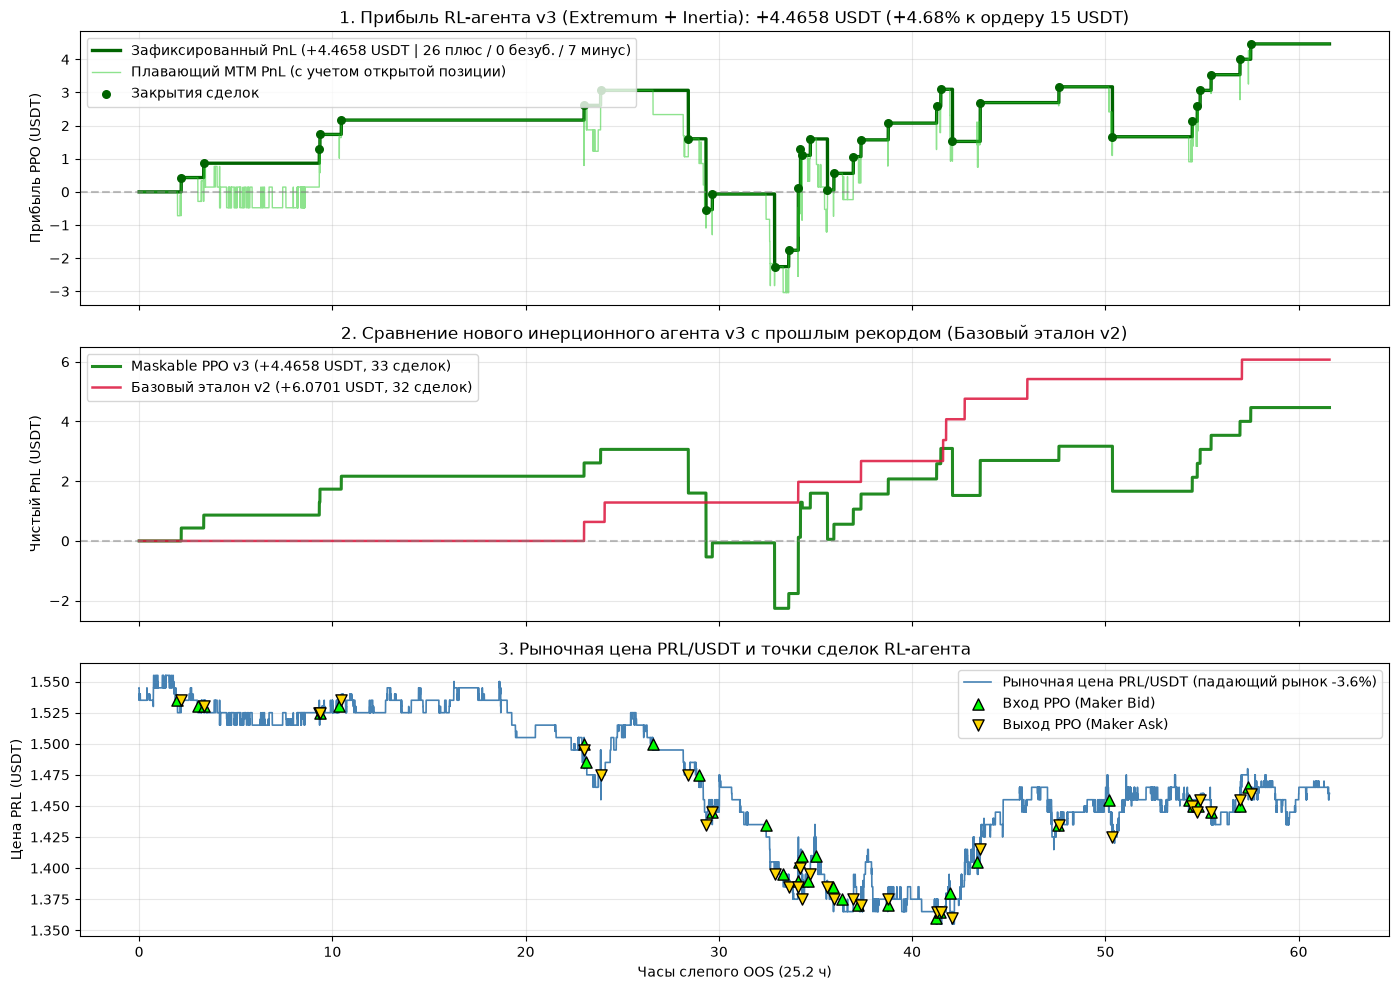

📈 СЛЕПОЙ OOS-БЕНЧМАРК МАСШТАБИРОВАНИЯ КАПИТАЛА ($8,000 ➔ $20,000 с шагом $2,000 | 83.86 ч)
Бюджет     | Режим                                | Чистый PnL ($) | PnL (%)   | MaxDD ($ / %)       | Сделок (Карус.) | $/сделку 
----------------------------------------------------------------------------------------------------------------------------
$8000      | v7.0 (Native 10-Slot + L1-L5 Cap)    |       +333.87$ |   +4.17% | $ 128.81 (1.61%) | 59     (3    ) | +5.659$
$10000     | v7.0 (Native 10-Slot + L1-L5 Cap)    |       +364.09$ |   +3.64% | $ 129.77 (1.30%) | 59     (3    ) | +6.171$
$12000     | v7.0 (Native 10-Slot + L1-L5 Cap)    |       +393.76$ |   +3.28% | $ 130.74 (1.09%) | 59     (3    ) | +6.674$
$14000     | v7.0 (Native 10-Slot + L1-L5 Cap)    |       +512.45$ |   +3.66% | $ 139.93 (1.00%) | 59     (3    ) | +8.686$
$16000     | v7.0 (Native 10-Slot + L1-L5 Cap)    |       +549.79$ |   +3.44% | $ 153.84 (0.96%) | 59     (3    ) | +9.318$
$18000     | v7.0 (Native 10-Slot

,budget_usd,pnl_usd,pnl_pct,max_dd_usd,max_dd_pct,trades,car_cycles,avg_pnl_per_trade
0,8000.0,333.87,4.17,128.81,1.61,59,3,5.6589
1,10000.0,364.09,3.64,129.77,1.30,59,3,6.1710
2,12000.0,393.76,3.28,130.74,1.09,59,3,6.6738
3,14000.0,512.45,3.66,139.93,1.00,59,3,8.6856
4,16000.0,549.79,3.44,153.84,0.96,59,3,9.3185
5,18000.0,586.90,3.26,167.75,0.93,59,3,9.9475
6,20000.0,623.83,3.12,181.66,0.91,59,3,10.5734


,entry_ts,exit_ts,hold_sec,entry_price,exit_action,net_pnl_usd,cum_pnl_usd
18,2026-11-03 11:07:06+03:00,2026-11-03 11:40:52+03:00,2026,1.37,Maker Ask (Passive),0.5054,1.0647
19,2026-11-03 11:56:58+03:00,2026-11-03 12:04:43+03:00,465,1.37,Maker Ask (Passive),0.5054,1.5701
20,2026-11-03 13:27:59+03:00,2026-11-03 13:29:24+03:00,85,1.37,Maker Ask (Passive),0.5054,2.0754
21,2026-11-03 15:58:58+03:00,2026-11-03 15:59:34+03:00,36,1.36,Maker Ask (Passive),0.5105,2.5859
22,2026-11-03 16:09:49+03:00,2026-11-03 16:12:31+03:00,162,1.36,Maker Ask (Passive),0.5105,3.0964
23,2026-11-03 16:40:16+03:00,2026-11-03 16:48:49+03:00,513,1.38,Maker Ask (Passive),-1.5737,1.5228
24,2026-11-03 18:04:19+03:00,2026-11-03 18:14:54+03:00,635,1.40,Maker Ask (Passive),1.1719,2.6947
25,2026-11-03 22:18:01+03:00,2026-11-03 22:19:09+03:00,68,1.43,Maker Ask (Passive),0.4762,3.1709
26,2026-11-04 00:54:02+03:00,2026-11-04 01:05:33+03:00,691,1.45,Maker Ask (Passive),-1.5069,1.6639
27,2026-11-04 05:02:11+03:00,2026-11-04 05:13:16+03:00,665,1.45,Maker Ask (Passive),0.4670,2.1309


In [4]:
# ШАГ 5/6: Тест боевой латентности (< 350 мс), слепой OOS-бенчмарк и стресс-тест масштабирования капитала (k .. 0k с шагом k)
import importlib
from IPython.display import display
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

df_ppo_trades, df_base_trades, df_capital_scaling = v7p.step5_run_validation_gate(
    coin="prl",
    replay_steps=10,
    scaling_budgets=(8000.0, 10000.0, 12000.0, 14000.0, 16000.0, 18000.0, 20000.0),
)
display(df_capital_scaling)
display(df_ppo_trades.tail(15))

In [5]:
# ШАГ 6/6: Безопасный деплой обновлённых весов на боевой VPS (81.19.137.18:2222) с сохранением кошелька и перезапуском демона
import importlib
import _tools.v7_retrain_pipeline as v7p
importlib.reload(v7p)

v7p.step6_deploy_to_vps_and_verify(coin="prl")

🚀 [ШАГ 6/6] ДЕПЛОЙ ОБНОВЛЕННЫХ ВЕСОВ v7.0 НА БОЕВОЙ VPS И ПЕРЕЗАПУСК ДЕМОНА
📦 Упаковано 1292 файлов (604.71 МБ)
💼 Сохранено состояние кошелька VPS: budget=$305.99, cash=$358.99, pos=0.0000 PRL
📤 Статус распаковки на VPS: UNPACK_OK
🚀 Перезапуск демона: 
⏳ Запрос статуса демона на VPS (81.19.137.18)...
📡 Статус демона на VPS (81.19.137.18): 🟢 РАБОТАЕТ НА СЕРВЕРЕ (PID=384381) | CPU=100% | RAM=765 МБ (19.5%) | Uptime=00:11
💼 Счет бота: Кэш=$358.99 | Позиция=0.0000 PRL (вход=$0.00) | Реализ. PnL=+50.6887$ | Сделок=170

📜 Онлайн-лог с сервера VPS (/opt/crypto_bot/data/logs/live_rl_trader.log, последние 25 строк):
----------------------------------------------------------------------------------------------------
[2026-11-04 22:00:44.509 MSK | #37255] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=+0.03t | Car=0%/0p Adv=0% | Equity=$358.99 (+53.00$) | 581.0 ms
  [2026-11-04 22:00:49.510 MSK | #37260] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=+0.03t | Car=0%/0p Adv=0% | Equity=$358.99 (+53.00$) |

In [6]:
# ОНЛАЙН-МОНИТОРИНГ: Проверка текущего статуса и живая трансляция лога с VPS
import importlib
import _tools.live_rl_trader as lrt
importlib.reload(lrt)

lrt.show_live_status(tail_lines=30)
# Для потокового просмотра в реальном времени раскомментируйте строку ниже:
# lrt.stream_live_log(duration_sec=60)

⏳ Запрос статуса демона на VPS (81.19.137.18)...
📡 Статус демона на VPS (81.19.137.18): 🟢 РАБОТАЕТ НА СЕРВЕРЕ (PID=384381) | CPU=100% | RAM=795 МБ (20.2%) | Uptime=00:11
💼 Счет бота: Кэш=$358.99 | Позиция=0.0000 PRL (вход=$0.00) | Реализ. PnL=+50.6887$ | Сделок=170

📜 Онлайн-лог с сервера VPS (/opt/crypto_bot/data/logs/live_rl_trader.log, последние 30 строк):
----------------------------------------------------------------------------------------------------
[2026-11-04 22:00:19.148 MSK | #37230] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=+0.00t | Car=0%/0p Adv=1% | Equity=$358.99 (+53.00$) | 492.0 ms
  [2026-11-04 22:00:24.149 MSK | #37235] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=+0.01t | Car=0%/0p Adv=1% | Equity=$358.99 (+53.00$) | 439.0 ms
  [2026-11-04 22:00:29.150 MSK | #37240] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=-0.03t | Car=3%/0p Adv=1% | Equity=$358.99 (+53.00$) | 685.0 ms
  [2026-11-04 22:00:34.151 MSK | #37245] Bid=1.53 Ask=1.54 | Act=HOLD_WAIT      | V=+0.02t | Ca